# Prelude

In [1]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [2]:
seaborn.set()

# Getting Data

In [3]:
data = pandas.read_csv(
    'results/SAT_120s.csv',
    index_col = ['problem', 'strategy'],
)

In [4]:
strategies = data.index.get_level_values('strategy').unique()

In [5]:
strategies

Index(['FirstAction', 'LeanCopCut', 'SATSolve'], dtype='object', name='strategy')

# Analysing

In [6]:
control = ['FirstAction', 'LeanCopCut']

In [7]:
data[data.solved]

status  solved  steps  time_ms           info error
problem    strategy                                                        
AGT001+1.p FirstAction  solved    True    4.0      1.0        Theorem   NaN
           LeanCopCut   solved    True    4.0      1.0        Theorem   NaN
           SATSolve     solved    True    3.0     35.0  Theorem (SAT)   NaN
AGT001+2.p FirstAction  solved    True    4.0      1.0        Theorem   NaN
           LeanCopCut   solved    True    4.0      1.0        Theorem   NaN
...                        ...     ...    ...      ...            ...   ...
TOP046+2.p SATSolve     solved    True    3.0  19453.0  Theorem (SAT)   NaN
TOP047+1.p SATSolve     solved    True    3.0     17.0  Theorem (SAT)   NaN
TOP047+2.p SATSolve     solved    True    3.0  16328.0  Theorem (SAT)   NaN
TOP048+1.p SATSolve     solved    True    3.0     54.0  Theorem (SAT)   NaN
TOP048+2.p SATSolve     solved    True    3.0  18279.0  Theorem (SAT)   NaN

[12366 rows x 6 columns]

In [8]:
data[data.solved].groupby(level = 1).size()

strategy
FirstAction    2155
LeanCopCut     2336
SATSolve       7875
dtype: int64

In [9]:
solved = data['solved'].unstack('strategy')

In [10]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction      78
LeanCopCut      143
SATSolve       6286
dtype: int64

# Results

<Axes: xlabel='strategy'>

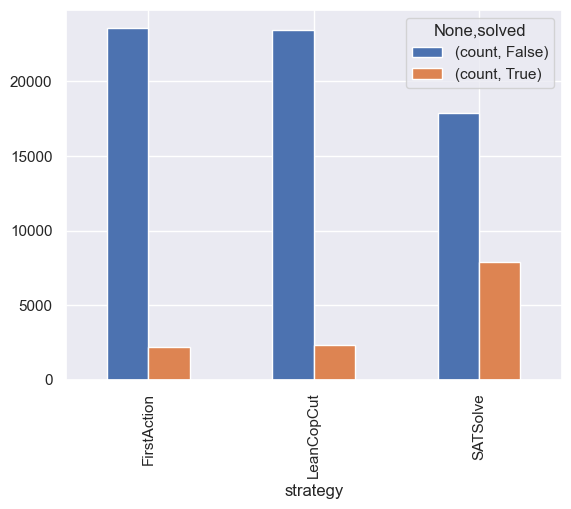

In [11]:
data.groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

<Axes: xlabel='winner', ylabel='loser'>

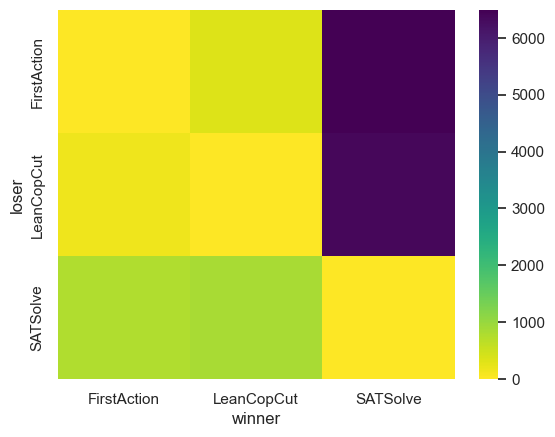

In [33]:
merged = pandas.merge(
    data.reset_index('strategy'),
    data.reset_index('strategy'),
    left_index = True,
    right_index = True,
    suffixes = ('_left', '_right'),
).set_index(['strategy_left', 'strategy_right'], append = True)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    .reset_index(['strategy_left', 'strategy_right'])
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [51]:
(
    merged
    .xs('SATSolve', level = 'strategy_right')
    .loc[lambda x: ~x.solved_left & x.solved_right]
    .loc[lambda x: x.index.get_level_values('problem').str.contains('-')]
    .sort_index()
    .sort_values('steps_right', kind = 'stable')
)

status_left  solved_left  steps_left  time_ms_left  \
problem    strategy_left                                                      
ALG004-1.p FirstAction       timeout        False         NaN           NaN   
           LeanCopCut        timeout        False         NaN           NaN   
ALG008-1.p FirstAction       timeout        False         NaN           NaN   
           LeanCopCut        timeout        False         NaN           NaN   
ALG303-1.p FirstAction       timeout        False         NaN           NaN   
...                              ...          ...         ...           ...   
ANA002-2.p LeanCopCut        timeout        False         NaN           NaN   
CAT002-4.p FirstAction       timeout        False         NaN           NaN   
           LeanCopCut        timeout        False         NaN           NaN   
CAT004-3.p FirstAction       timeout        False         NaN           NaN   
           LeanCopCut        timeout        False         NaN           NaN   

                         info_left error_left status_right  solved_right  \
problem    strategy_left                                                   
ALG004-1.p FirstAction         NaN        NaN       solved          True   
           LeanCopCut          NaN        NaN       solved          True   
ALG008-1.p FirstAction         NaN        NaN       solved          True   
           LeanCopCut          NaN        NaN       solved          True   
ALG303-1.p FirstAction         NaN        NaN       solved          True   
...                            ...        ...          ...           ...   
ANA002-2.p LeanCopCut          NaN        NaN       solved          True   
CAT002-4.p FirstAction         NaN        NaN       solved          True   
           LeanCopCut          NaN        NaN       solved          True   
CAT004-3.p FirstAction         NaN        NaN       solved          True   
           LeanCopCut          NaN        NaN       solved          True   

                          steps_right  time_ms_right     info_right  \
problem    strategy_left                                              
ALG004-1.p FirstAction            3.0            1.0  Theorem (SAT)   
           LeanCopCut             3.0            1.0  Theorem (SAT)   
ALG008-1.p FirstAction            3.0            1.0  Theorem (SAT)   
           LeanCopCut             3.0            1.0  Theorem (SAT)   
ALG303-1.p FirstAction            3.0            3.0  Theorem (SAT)   
...                               ...            ...            ...   
ANA002-2.p LeanCopCut           521.0        26556.0        Theorem   
CAT002-4.p FirstAction          566.0        38494.0        Theorem   
           LeanCopCut           566.0        38494.0        Theorem   
CAT004-3.p FirstAction          624.0        86567.0        Theorem   
           LeanCopCut           624.0        86567.0        Theorem   

                         error_right  
problem    strategy_left              
ALG004-1.p FirstAction           NaN  
           LeanCopCut            NaN  
ALG008-1.p FirstAction           NaN  
           LeanCopCut            NaN  
ALG303-1.p FirstAction           NaN  
...                              ...  
ANA002-2.p LeanCopCut            NaN  
CAT002-4.p FirstAction           NaN  
           LeanCopCut            NaN  
CAT004-3.p FirstAction           NaN  
           LeanCopCut            NaN  

[3801 rows x 12 columns]